# 1.05. Подбор уровня значимости и размера выборки теста

**План занятия**

1. Что считать успехом эксперимента в бизнесе и какие затраты и выгоды он создаёт.
2. Какие параметры теста мы можем менять.
3. Распределение ожидаемых эффектов и точка безубыточности.
4. Затраты и выгоды с поправкой на риск, отношение выгоды к риску.
5. Поиск оптимальных $\alpha$ и $n$ и сравнение со стандартным дизайном.
6. Разбор вопроса «а что, если $\alpha = 0.5$?».
7. Ограничения модели.

Лекция опирается на 11-ю главу книги Georgiev G.Z. *Statistical Methods in Online A/B Testing*. Традиционный подход ($\alpha = 0.05$, $\beta = 0.2$, произвольный минимальный интересующий эффект, MEI) игнорирует структуру затрат и выгод конкретного теста. Мы построим модель, которая подбирает $\alpha$ и $n$ под финансовый результат, и посмотрим, что она даёт и где её можно обмануть.

### Библиотеки и общие параметры

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'


def spaced(value: float) -> str:
    """Форматирует число с пробелами между разрядами."""
    return f'{value:,.0f}'.replace(',', ' ')

Для расчётов возьмём синтетический пример: интернет-магазин тестирует изменение checkout-страницы, которое может повлиять на вероятность покупки. Важно не только понять, есть ли эффект, но и оценить, оправданы ли тест и внедрение нового варианта с точки зрения бизнеса.

Параметры кейса:

* базовая конверсия: 5%;
* число пользователей в неделю: 50 000;
* недельная выручка: 3 000 000 ₽;
* фиксированные затраты на тест: 180 000 ₽;
* стоимость внедрения: 120 000 ₽;
* стоимость отката решения: 250 000 ₽;
* дополнительные расходы на поддержку: 20 000 ₽ в месяц;
* горизонт планирования: 12 месяцев от старта теста.

Считаем, что относительный рост конверсии даёт такой же относительный рост выручки.

In [2]:
@dataclass
class BusinessCase:
    """Параметры бизнес-кейса."""
    baseline_cr: float = 0.05
    weekly_users: int = 50_000
    weekly_revenue: float = 3_000_000
    fixed_test_cost: float = 180_000
    implementation_cost: float = 120_000
    rollback_cost: float = 250_000
    monthly_maintenance: float = 20_000
    horizon_months: float = 12

    @property
    def horizon_weeks(self) -> float:
        return self.horizon_months * 52 / 12

    @property
    def maintenance_cost(self) -> float:
        return self.monthly_maintenance * self.horizon_months

    @property
    def break_even(self) -> float:
        """Эффект, при котором выручка за горизонт покрывает затраты на тест, внедрение и поддержку."""
        costs = self.fixed_test_cost + self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)


case = BusinessCase()

## Определение «успеха» для бизнес-эксперимента

В науке любой корректно проведённый эксперимент полезен, потому что увеличивает знание. В бизнесе критерий иной.

**Ключевой вопрос перед тестом:**
> «Основываясь на наших ограниченных ресурсах, какое действие следует предпринять, чтобы улучшить KPI наиболее экономически эффективным и устойчивым способом?»

**ROI-оптимальный тест** — это тест, дизайн которого максимизирует ожидаемую отдачу. Отдельный такой тест может закончиться и потерями, но в среднем по многим решениям такой дизайн выгоднее других.

Перед существенными действиями нужно ответить на три вопроса с учётом всех рисков:

* Каков общий доход, на который могут повлиять запланированные действия?
* Каков ожидаемый положительный эффект от этих действий?
* Каковы ожидаемые общие затраты, включая постоянные и связанные с рисками?

Оптимизируя первые два параметра и минимизируя третий, мы приближаемся к оптимальной рентабельности инвестиций:

$$
ROI = \frac{\text{Gain} - \text{Costs}}{\text{Costs}}, \quad \text{Gain} = \text{Effect} \times \text{Impact}
$$

Георгиев в книге называет ROI отношение $\text{Gain} / \text{Costs}$. Мы используем стандартное определение: при нём $ROI = 0$ означает, что выгоды только покрыли затраты.

## Затраты, выгоды, риски и вознаграждения

Чтобы разобраться в затратах и выгодах, рассмотрим временную шкалу типичного теста. Затраты возникают на этапе планирования и разработки, во время самого теста и после внедрения выбранного решения. Выгоды возникают только во время теста и после внедрения.

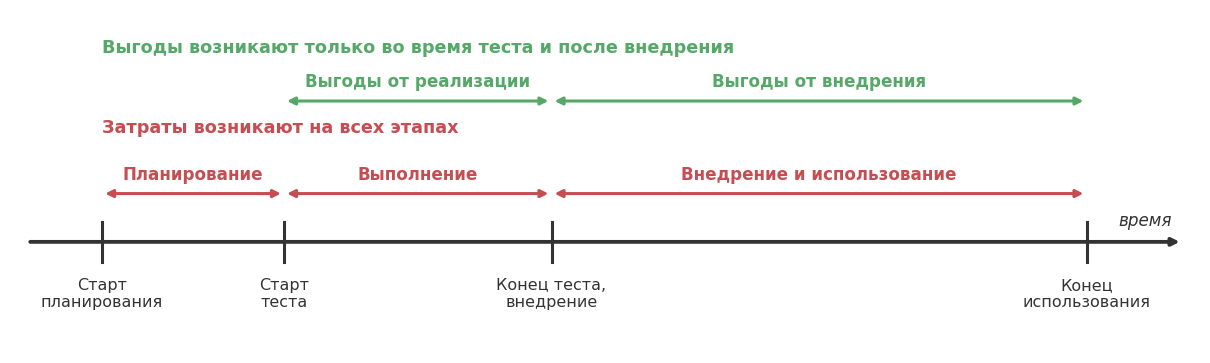

Затраты можно разделить на два типа:

1. **Фиксированные** (единовременные или бессрочные).
2. **Связанные с риском.** Говоря о них в деньгах с учётом вероятности, мы будем называть их **затратами с поправкой на риск** (risk-adjusted).

Выгоды точно так же могут быть связаны с риском, и мы будем говорить о **выгодах с поправкой на риск**. Фиксированных выгод не существует: если выгоду можно получить независимо от результата теста, она с тестом не связана.

«Фиксированные» в «фиксированных затратах» означает, что они возникают с вероятностью $P=1$ независимо от результата теста, но не означает, что их сумма постоянна. Например, подписка на сервис для тестирования наступает с вероятностью 1, но её итоговая сумма зависит от длительности использования.

Отдельно стоит учитывать **стоимость отмены решения**, которое окажется ошибочным. Тривиальные изменения интерфейса или текста легко и дёшево отменить. Другие решения практически необратимы, например изменения, затрагивающие отношения с партнёрами или крупные инвестиции в инфраструктуру. Для таких решений стоимость ошибки сильно меняет расчёт, а оптимальный порог значимости становится строже.

## Параметры теста и их связь с затратами и выгодами

Какие параметры теста мы можем менять, чтобы получить оптимальное соотношение риска и выгоды?

Два статистических параметра:

1. порог статистической значимости $\alpha$;
2. размер выборки $n$.

Размер выборки определяет мощность $(1-\beta)$ и минимальный надёжно обнаруживаемый эффект MDE. Он же задаёт длительность теста, потому что поток пользователей ограничен.

Три параметра дизайна:

3. определение нулевой гипотезы (superiority, non-inferiority) и набор метрик;
4. количество вариантов (A/B, A/B/n);
5. схема мониторинга (фиксированный горизонт или последовательный тест).

Нулевая гипотеза, метрики и варианты обычно определяются внешней информацией. Георгиев также считает, что последовательная схема почти всегда выгоднее по ROI (она разбирается в [лекции про последовательное тестирование](<../../../2. Квази-эксперименты/Теоретический блок/01. Последовательное тестирование/lecture.ipynb>)). Поэтому сосредоточимся на двух параметрах: $n$ и $\alpha$.

Параметры связаны между собой. Меньшая выборка делает тест короче и дешевле, но снижает мощность и повышает риск пропустить хороший вариант. Большая выборка повышает мощность, но откладывает внедрение. Из-за этих компромиссов оптимальные значения приходится искать перебором.

## Распределение ожидаемых эффектов

Истинный эффект $\theta$ заранее неизвестен, поэтому в модели задаётся **распределение ожидаемых эффектов** $\pi(\theta)$. Оно отражает, какие значения эффекта мы считаем более или менее правдоподобными до эксперимента, и обычно строится по истории похожих тестов.

**Важные предостережения:**

1. Это априорное распределение, но сам анализ остаётся частотным: распределение используется только для выбора $\alpha$ и $n$ на этапе дизайна.
2. Равномерное распределение не означает «я ничего не знаю»: это сильное утверждение о том, что все эффекты равновероятны.
3. Есть проблема референтного класса: слишком узкий круг похожих тестов даёт мало данных, а слишком широкий делает оценку неточной для конкретного случая.

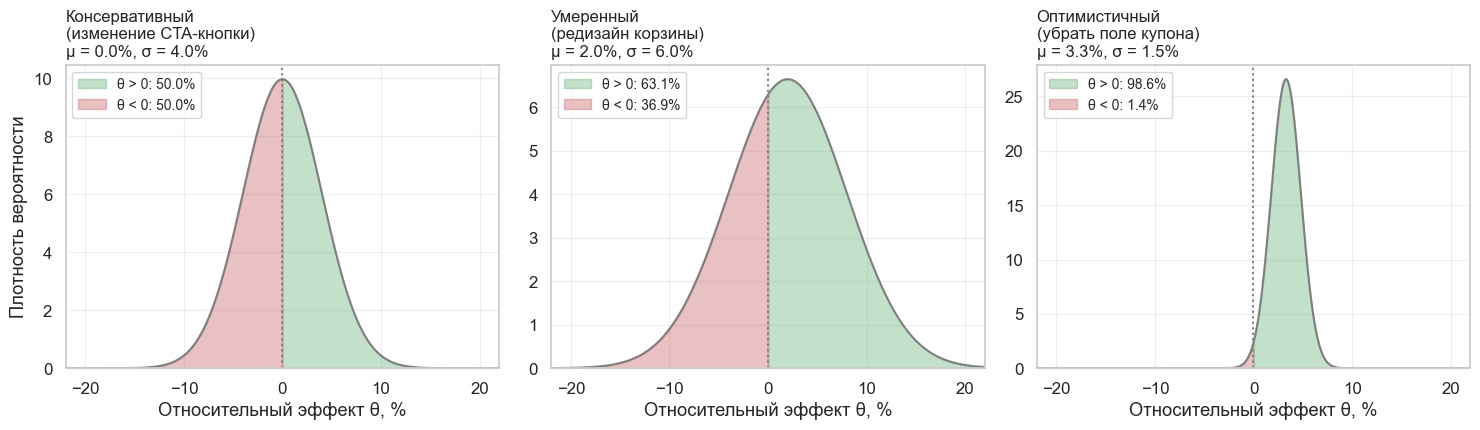

In [3]:
x_eff = np.linspace(-0.22, 0.22, 600)
scenarios = [
    ('Консервативный\n(изменение CTA-кнопки)', 0.00, 0.04),
    ('Умеренный\n(редизайн корзины)', 0.02, 0.06),
    ('Оптимистичный\n(убрать поле купона)', 0.033, 0.015),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, loc, scale) in zip(axes, scenarios):
    prior = norm(loc, scale)
    y = prior.pdf(x_eff)
    ax.plot(x_eff * 100, y, color=GRAY, linewidth=1.5)
    ax.fill_between(x_eff * 100, y, where=x_eff >= 0, color=GREEN, alpha=0.35, label=f'θ > 0: {prior.sf(0):.1%}')
    ax.fill_between(x_eff * 100, y, where=x_eff <= 0, color=RED, alpha=0.35, label=f'θ < 0: {prior.cdf(0):.1%}')
    ax.axvline(0, color=GRAY, linestyle=':', linewidth=1.5)
    ax.set_title(f'{title}\nμ = {loc:.1%}, σ = {scale:.1%}', loc='left', fontsize=12)
    ax.set_xlabel('Относительный эффект θ, %')
    ax.set_xlim(-22, 22)
    ax.set_ylim(bottom=0)
    ax.legend(loc='upper left', fontsize=10)
axes[0].set_ylabel('Плотность вероятности')
plt.tight_layout()
plt.show()

| Сценарий | Параметры | P(θ > 0) | Интерпретация |
| :--- | :--- | :---: | :--- |
| **Консервативный** (изменение CTA-кнопки) | μ = 0%, σ = 4% | 50.0% | Эффект скорее всего близок к нулю и с равной вероятностью будет как положительным, так и отрицательным. |
| **Умеренный** (редизайн корзины) | μ = 2%, σ = 6% | 63.1% | Ожидаем небольшой положительный сдвиг, но разброс велик и риск негативного исхода заметен (около 37%). |
| **Оптимистичный** (убрать поле купона) | μ = 3.3%, σ = 1.5% | 98.6% | Высокая уверенность в положительном эффекте, риск негативного исхода минимален (около 1.4%). |

Выбор распределения сильно влияет на оценку рисков, поэтому ниже мы отдельно проверим чувствительность результата к нему.

В нашем кейсе с checkout-страницей для простоты будем считать, что эффект распределён нормально вокруг нуля с $\sigma = 3\%$. Положительные и отрицательные эффекты заранее считаются одинаково возможными.

In [4]:
effect_grid = np.linspace(-0.10, 0.10, 1000)  # сетка возможных истинных эффектов

prior_mu = 0.0
prior_sigma = 0.03

density = norm.pdf(effect_grid, loc=prior_mu, scale=prior_sigma)
density /= np.trapezoid(density, effect_grid)  # сетка обрезает хвосты, поэтому нормируем заново

## Расчёт отношения выгоды к риску

### Точка безубыточности

Первый шаг к расчёту ROI — определить **точку безубыточности по фиксированным затратам (fixed-cost break-even point)**. Обычно это очень небольшой относительный прирост, часто ниже 1%, потому что затраты на большинство тестов невелики по сравнению с их влиянием за время использования.

В точке безубыточности выгода равна затратам, то есть $ROI = 0$:

$$
\text{break-even effect} \times \text{Revenue} = \text{Fixed Costs}
$$

$$
\text{break-even effect} = \frac{\text{Fixed Costs}}{\text{Revenue}} = \frac{\text{Fixed Costs}}{\text{Weekly Revenue} \times \text{Effect Horizon (weeks)}}
$$

Здесь в затраты входят тест, внедрение и поддержка: мы считаем, сколько должен принести запущенный вариант, чтобы вся затея окупилась. Точка равна нулю только в редком случае, когда побочные эффекты изменения в точности компенсируют эти затраты.

Точка безубыточности определяет, что такое успех: улучшение метрики само по себе ничего не говорит о затратах на его внедрение и поддержку. Поэтому и тест мы будем строить вокруг неё.

Суммарные фиксированные издержки: 540 000 ₽
Fixed-cost break-even point: 0.346% относительного uplift


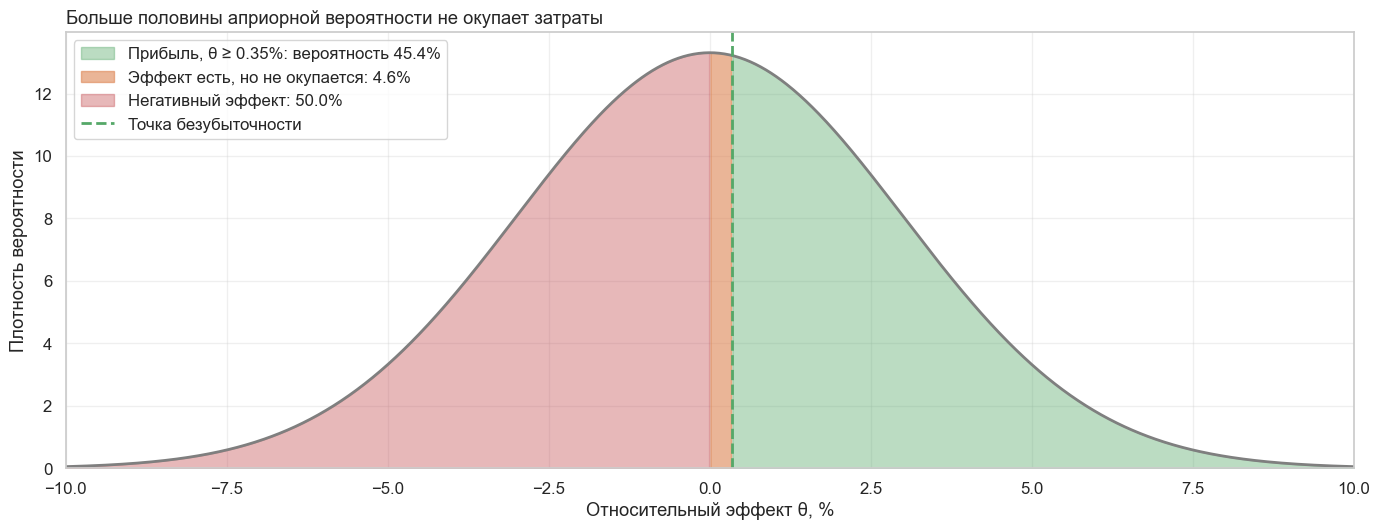

In [5]:
fixed_costs = case.fixed_test_cost + case.implementation_cost + case.maintenance_cost
break_even = case.break_even
print(f"Суммарные фиксированные издержки: {spaced(fixed_costs)} ₽")
print(f"Fixed-cost break-even point: {break_even:.3%} относительного uplift")

prior = norm(prior_mu, prior_sigma)
x = effect_grid * 100

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(x, density, color=GRAY, linewidth=2)
ax.fill_between(x, density, where=effect_grid >= break_even, color=GREEN, alpha=0.4,
                label=f'Прибыль, θ ≥ {break_even:.2%}: вероятность {prior.sf(break_even):.1%}')
ax.fill_between(x, density, where=(effect_grid > 0) & (effect_grid < break_even), color='#DD8452', alpha=0.6,
                label=f'Эффект есть, но не окупается: {prior.cdf(break_even) - prior.cdf(0):.1%}')
ax.fill_between(x, density, where=effect_grid <= 0, color=RED, alpha=0.4, label=f'Негативный эффект: {prior.cdf(0):.1%}')
ax.axvline(break_even * 100, color=GREEN, linestyle='--', linewidth=2, label='Точка безубыточности')
ax.set_title('Больше половины априорной вероятности не окупает затраты', loc='left')
ax.set_xlabel('Относительный эффект θ, %')
ax.set_ylabel('Плотность вероятности')
ax.set_xlim(-10, 10)
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Значения левее точки безубыточности не окупаются даже при положительном uplift.

Расчёты ниже предполагают биномиальную метрику, например конверсию покупок, но аналогично работают и для непрерывных показателей вроде ARPU.

### Затраты и выгоды с поправкой на риск

Для расчёта нужны:

* затраты, которые мы несём независимо от результата: $Cost_f$;
* затраты, которые появляются только при внедрении: $Cost_d(\theta)$;
* базовая конверсия;
* число пользователей за бизнес-цикл;
* выручка за бизнес-цикл.

Обозначим $Rev_{\text{test}}$ как выручку, затронутую тестом: половина недельной выручки, умноженная на длительность теста $T$. Через $Rev_{\text{post}}$ обозначим выручку после теста, умноженную на оставшееся время $H - T$, где $H$ — горизонт планирования. Важно, что $Rev_{\text{post}}$ уменьшается с ростом теста: каждая неделя теста откладывает внедрение. Именно это делает слишком длинные тесты невыгодными.

**Затраты с поправкой на риск** получаем интегрированием по распределению ожиданий:

$$
Cost_{RA} = Cost_f + \int_{a}^{b} f_{c}(\theta) \, d\theta
$$

$$
\boxed{
f_{c}(\theta) = \pi(\theta) \cdot \Big( \max(-\theta \cdot Rev_{\text{test}}, 0) + \big[ \max(-\theta \cdot Rev_{\text{post}}, 0) + Cost_{d}(\theta) \big] \cdot POW(\alpha; \theta) \Big)
}
$$

Здесь:

* $a$ и $b$ — нижний и верхний пределы распределения ожиданий;
* $POW(\alpha; \theta)$ — вероятность внедрения при истинном эффекте $\theta$;
* $Cost_{d}(\theta)$ — стоимость внедрения и поддержки, а если $\theta$ ниже точки безубыточности, то ещё и стоимость отката.

**Выгоды с поправкой на риск** считаются аналогично. $Gain_{d}$ — разовая выгода от внедрения, в нашем кейсе её нет:

$$
Gain_{RA} = \int_{a}^{b} f_{g}(\theta) \, d\theta
$$

$$
\boxed{
f_{g}(\theta) = \pi(\theta) \cdot \Big( \max(\theta \cdot Rev_{\text{test}}, 0) + \big[ \max(\theta \cdot Rev_{\text{post}}, 0) + Gain_{d} \big] \cdot POW(\alpha; \theta) \Big)
}
$$

#### Вероятность внедрения

В этом фреймворке решение о внедрении связывается не с проверкой нулевого эффекта, а с проверкой того, превышает ли эффект **точку безубыточности**. Рассмотрим одностороннюю гипотезу:

$$
H_0:\ \theta \leq \theta_{BE}, \qquad H_1:\ \theta > \theta_{BE}
$$

Новый вариант достоин внедрения, только если есть статистические основания считать, что его эффект выше уровня экономической оправданности.

Пусть $\hat{\delta}$ — оценка абсолютной разницы конверсий, $\delta_{BE}$ — разница, соответствующая точке безубыточности, а $SE$ — стандартная ошибка оценки. Решение о внедрении принимается, если:

$$
\frac{\hat{\delta} - \delta_{BE}}{SE} > z_{1-\alpha} \quad \Rightarrow \quad \hat{\delta} > \delta_{BE} + z_{1-\alpha}\cdot SE
$$

Обратите внимание: здесь $\alpha$ **односторонний** и равен вероятности внедрения при $\theta = \theta_{BE}$. Привычный двусторонний уровень 0.05 соответствует одностороннему 0.025.

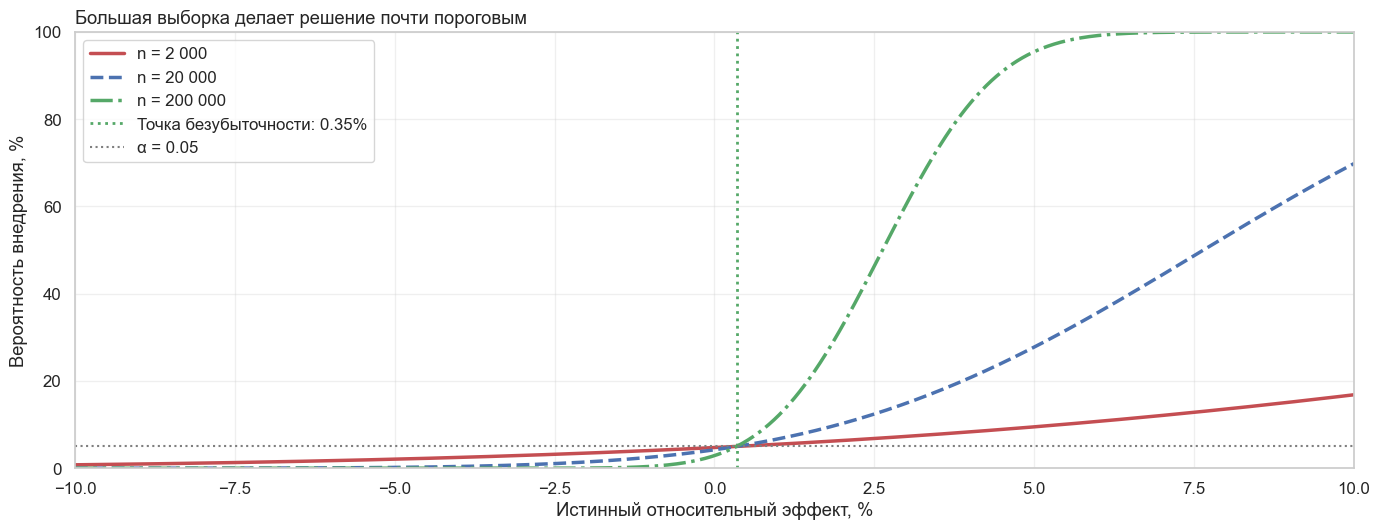

In [6]:
def implementation_probability(
    p_control: float,
    relative_effect: np.ndarray,
    break_even_effect: float,
    n_per_group: np.ndarray,
    alpha: np.ndarray = 0.05
) -> np.ndarray:
    """Считает вероятность внедрения при истинном эффекте relative_effect, аргументы могут быть массивами."""
    p_true = np.clip(p_control * (1 + relative_effect), 1e-6, 1 - 1e-6)

    # Истинная разница конверсий и разница, соответствующая точке безубыточности
    delta_true = p_true - p_control
    delta_be = p_control * break_even_effect

    se = np.sqrt(p_control * (1 - p_control) / n_per_group + p_true * (1 - p_true) / n_per_group)

    # Вероятность того, что оценка эффекта окажется выше порога внедрения
    z_crit = norm.ppf(1 - alpha)
    return norm.sf(z_crit - (delta_true - delta_be) / se)


fig, ax = plt.subplots(figsize=(14, 5.5))
for n_val, color, style in [(2_000, RED, '-'), (20_000, BLUE, '--'), (200_000, GREEN, '-.')]:
    probability = implementation_probability(case.baseline_cr, effect_grid, break_even, n_val)
    ax.plot(effect_grid * 100, probability * 100, color=color, linestyle=style, linewidth=2.5, label=f'n = {spaced(n_val)}')
ax.axvline(break_even * 100, color=GREEN, linestyle=':', linewidth=2, label=f'Точка безубыточности: {break_even:.2%}')
ax.axhline(5, color=GRAY, linestyle=':', linewidth=1.5, label='α = 0.05')
ax.set_title('Большая выборка делает решение почти пороговым', loc='left')
ax.set_xlabel('Истинный относительный эффект, %')
ax.set_ylabel('Вероятность внедрения, %')
ax.set_xlim(-10, 10)
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Чем больше выборка, тем выше вероятность внедрения для эффектов выше точки безубыточности и тем ниже она для эффектов ниже этой точки. Все кривые проходят через одну точку: при $\theta = \theta_{BE}$ вероятность внедрения равна $\alpha$ при любом $n$.

### Отношение выгоды к риску

Определим отношение выгоды к риску:

$$
RR = \frac{Gain_{RA}}{Cost_{RA}}
$$

Значение $RR > 1$ означает, что ожидаемая выгода превышает ожидаемые затраты, а $ROI = RR - 1$. Георгиев и многие инструменты используют обратное отношение (risk/reward, например 1/4), где чем меньше, тем лучше. Мы будем смотреть на вариант, где чем больше, тем лучше.

Вместе с отношением будем считать **ожидаемую чистую прибыль**: $Net = Gain_{RA} - Cost_{RA}$. Отношение и прибыль отвечают на разные вопросы, и ниже мы увидим, что они выбирают разные дизайны.

#### Реализация

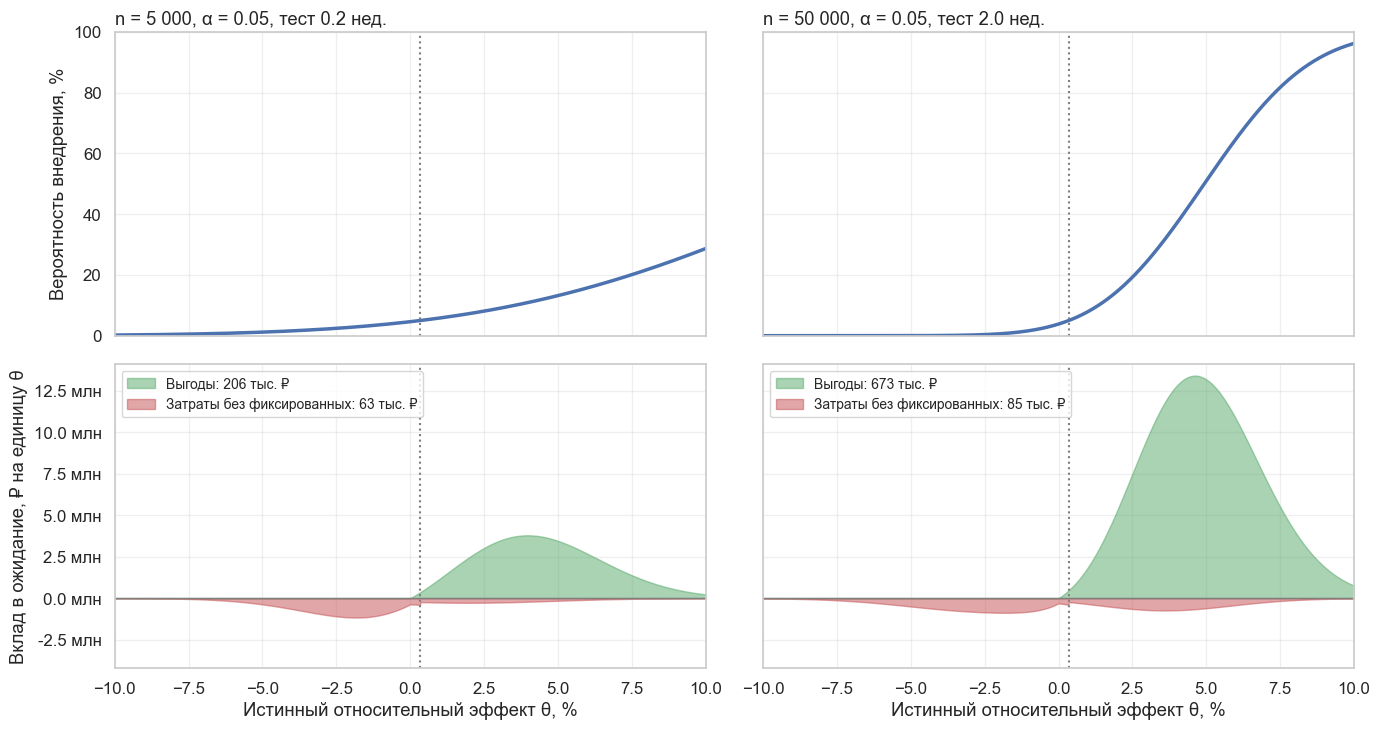

,n = 5000,n = 50000
"Выгоды, ₽",205687.25,673368.40
"Затраты, ₽",243092.09,265329.49
"Чистая прибыль, ₽",-37404.84,408038.91
RR,0.85,2.54


In [7]:
def evaluate_design(
    case: BusinessCase,
    effect_grid: np.ndarray,
    density: np.ndarray,
    n_per_group: np.ndarray,
    alpha: np.ndarray
) -> dict:
    """
    Рассчитывает выгоды и затраты с поправкой на риск.

    n_per_group и alpha можно передать массивами: тогда их формы должны
    согласовываться с осью эффектов, которая всегда идёт последней.
    """
    n_per_group = np.asarray(n_per_group, dtype=float)
    probability = implementation_probability(case.baseline_cr, effect_grid, case.break_even, n_per_group, alpha)

    test_weeks = 2 * n_per_group / case.weekly_users
    post_weeks = np.maximum(case.horizon_weeks - test_weeks, 0)  # длинный тест откладывает внедрение

    # Половина пользователей видит новый вариант во время теста
    test_value = case.weekly_revenue * effect_grid * test_weeks * 0.5
    post_value = case.weekly_revenue * effect_grid * post_weeks * probability

    # Затраты только при внедрении, откат нужен, если вариант не окупается
    decision_costs = (case.implementation_cost + case.maintenance_cost
                      + case.rollback_cost * (effect_grid < case.break_even)) * probability

    gains = (np.maximum(test_value, 0) + np.maximum(post_value, 0)) * density
    losses = (np.maximum(-test_value, 0) + np.maximum(-post_value, 0) + decision_costs) * density

    expected_gain = np.trapezoid(gains, effect_grid, axis=-1)
    expected_loss = case.fixed_test_cost + np.trapezoid(losses, effect_grid, axis=-1)

    return {
        'probability': probability,
        'gains': gains,
        'losses': losses,
        'expected_gain': expected_gain,
        'expected_loss': expected_loss,
        'rr': expected_gain / expected_loss,
        'net': expected_gain - expected_loss,
    }


def describe_design(result: dict) -> pd.Series:
    """Собирает итоговые показатели дизайна."""
    return pd.Series({
        'Выгоды, ₽': result['expected_gain'],
        'Затраты, ₽': result['expected_loss'],
        'Чистая прибыль, ₽': result['net'],
        'RR': result['rr'],
    })


def plot_risk_adjusted(designs: list) -> None:
    """Показывает вероятность внедрения и подынтегральные выгоды и затраты для списка дизайнов (n, alpha)."""
    results = [evaluate_design(case, effect_grid, density, n, alpha) for n, alpha in designs]
    limit = max(max(r['gains'].max(), r['losses'].max()) for r in results) * 1.05
    x = effect_grid * 100

    fig, axes = plt.subplots(2, len(designs), figsize=(7 * len(designs), 7.5), sharex=True, sharey='row', squeeze=False)
    for column, ((n, alpha), result) in enumerate(zip(designs, results)):
        top, bottom = axes[0, column], axes[1, column]
        top.plot(x, result['probability'] * 100, color=BLUE, linewidth=2.5)
        top.axvline(break_even * 100, color=GRAY, linestyle=':', linewidth=1.5)
        top.set_ylim(0, 100)
        top.set_title(f'n = {spaced(n)}, α = {alpha}, тест {2 * n / case.weekly_users:.1f} нед.', loc='left')

        bottom.fill_between(x, result['gains'], color=GREEN, alpha=0.5, label=f"Выгоды: {spaced(result['expected_gain'] / 1000)} тыс. ₽")
        bottom.fill_between(x, -result['losses'], color=RED, alpha=0.5, label=f"Затраты без фиксированных: {spaced((result['expected_loss'] - case.fixed_test_cost) / 1000)} тыс. ₽")
        bottom.axhline(0, color=GRAY, linewidth=1)
        bottom.axvline(break_even * 100, color=GRAY, linestyle=':', linewidth=1.5)
        bottom.set_ylim(-0.3 * limit, limit)
        bottom.set_xlabel('Истинный относительный эффект θ, %')
        bottom.legend(loc='upper left', fontsize=10)

    axes[0, 0].set_ylabel('Вероятность внедрения, %')
    axes[1, 0].set_ylabel('Вклад в ожидание, ₽ на единицу θ')
    axes[1, 0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e6:.1f} млн'))
    plt.xlim(-10, 10)
    plt.tight_layout()
    plt.show()


designs_example = [(5_000, 0.05), (50_000, 0.05)]
plot_risk_adjusted(designs_example)
pd.DataFrame({f'n = {n}': describe_design(evaluate_design(case, effect_grid, density, n, alpha))
              for n, alpha in designs_example}).round(2)

Как читать графики. Верхний ряд показывает вероятность внедрения. Нижний ряд показывает вклад каждого значения $\theta$ в ожидание: он уже взвешен распределением $\pi(\theta)$, поэтому площадь зелёной области равна выгодам, а красной равна затратам без 180 тыс. ₽ на тест.

При $n = 5\,000$ тест почти ничего не решает: даже сильные эффекты редко внедряются, и фиксированные затраты не окупаются (убыток около 37 тыс. ₽, $RR = 0.85$). При $n = 50\,000$ тот же уровень значимости даёт прибыль около 408 тыс. ₽ и $RR = 2.54$.

Формулы можно проверить независимо: разыграем тот же процесс целиком. Берём случайный истинный эффект из априорного распределения, генерируем конверсии в группах, применяем правило внедрения и считаем деньги.

In [8]:
def simulate_design(case: BusinessCase, n_per_group: int, alpha: float, n_sims: int = 400_000, seed: int = 42) -> tuple:
    """Оценивает среднюю прибыль дизайна полным разыгрыванием экспериментов."""
    rng = np.random.default_rng(seed)
    theta = rng.normal(prior_mu, prior_sigma, n_sims)
    theta = theta[np.abs(theta) <= effect_grid.max()]  # та же область интегрирования, что и в формулах

    p_control = case.baseline_cr
    p_treatment = p_control * (1 + theta)
    control = rng.binomial(n_per_group, p_control, theta.size) / n_per_group
    treatment = rng.binomial(n_per_group, p_treatment) / n_per_group

    se = np.sqrt(control * (1 - control) / n_per_group + treatment * (1 - treatment) / n_per_group)
    ship = (treatment - control - p_control * case.break_even) / se > norm.ppf(1 - alpha)

    test_weeks = 2 * n_per_group / case.weekly_users
    post_weeks = case.horizon_weeks - test_weeks
    profit = case.weekly_revenue * theta * test_weeks * 0.5 - case.fixed_test_cost
    profit += ship * (case.weekly_revenue * theta * post_weeks - case.implementation_cost - case.maintenance_cost
                      - case.rollback_cost * (theta < case.break_even))
    return profit.mean(), profit.std() / np.sqrt(theta.size)


for n, alpha in designs_example:
    formula = evaluate_design(case, effect_grid, density, n, alpha)['net']
    simulated, error = simulate_design(case, n, alpha)
    print(f"n = {spaced(n)}: формула {spaced(formula)} ₽, симуляция {spaced(simulated)} ± {spaced(1.96 * error)} ₽")

n = 5 000: формула -37 405 ₽, симуляция -34 741 ± 3 761 ₽
n = 50 000: формула 408 039 ₽, симуляция 410 599 ± 6 325 ₽


#### Замечания о сложных ситуациях

1. При последовательном мониторинге длительность теста зависит от неизвестного истинного эффекта. Зная распределение ожиданий, можно рассчитать среднюю длительность и использовать её для оценки затронутого дохода.
2. Увеличение числа вариантов вводит дополнительные допущения при расчёте выборки и иногда требует отдельного распределения ожиданий для каждого варианта. Математика усложняется, но логика вычислений остаётся той же.

## Поиск оптимальных $\alpha$ и $n$

Рассчитаем выгоды и затраты для всех сочетаний $\alpha$ и $n$ и сравним дизайны.

У поиска есть две типичные ловушки:

* **Край сетки.** Если оптимум лежит на границе сетки, настоящего оптимума мы не нашли. Поэтому сетка по $n$ идёт до 600 тыс. на группу, то есть почти до половины горизонта.
* **Критерий.** Максимум отношения $RR$ и максимум прибыли $Net$ в общем случае не совпадают, поэтому посмотрим на оба.

In [9]:
alpha_grid = np.array([0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8])
n_grid = np.unique(np.round(np.geomspace(1_000, 600_000, 60), -2)).astype(int)


def design_grid(case: BusinessCase, effects: np.ndarray, weights: np.ndarray) -> dict:
    """Считает RR и прибыль для всех сочетаний alpha и n."""
    return evaluate_design(case, effects, weights, n_grid[None, :, None], alpha_grid[:, None, None])


def best_design(grid: dict, metric: str) -> tuple:
    """Находит alpha и n с максимальным значением метрики."""
    row, column = np.unravel_index(np.argmax(grid[metric]), grid[metric].shape)
    return alpha_grid[row], n_grid[column], grid['rr'][row, column], grid['net'][row, column]


grid = design_grid(case, effect_grid, density)
results_df = pd.DataFrame([best_design(grid, 'rr'), best_design(grid, 'net')],
                          index=['Максимум RR', 'Максимум прибыли'],
                          columns=['α', 'n на группу', 'RR', 'Чистая прибыль, ₽'])
results_df['Длительность, дней'] = (results_df['n на группу'] * 2 / case.weekly_users * 7).round(1)
results_df.round(3)

,α,n на группу,RR,"Чистая прибыль, ₽","Длительность, дней"
Максимум RR,0.2,105900,3.443,947755.530,29.7
Максимум прибыли,0.5,146600,3.003,1081315.679,41.0


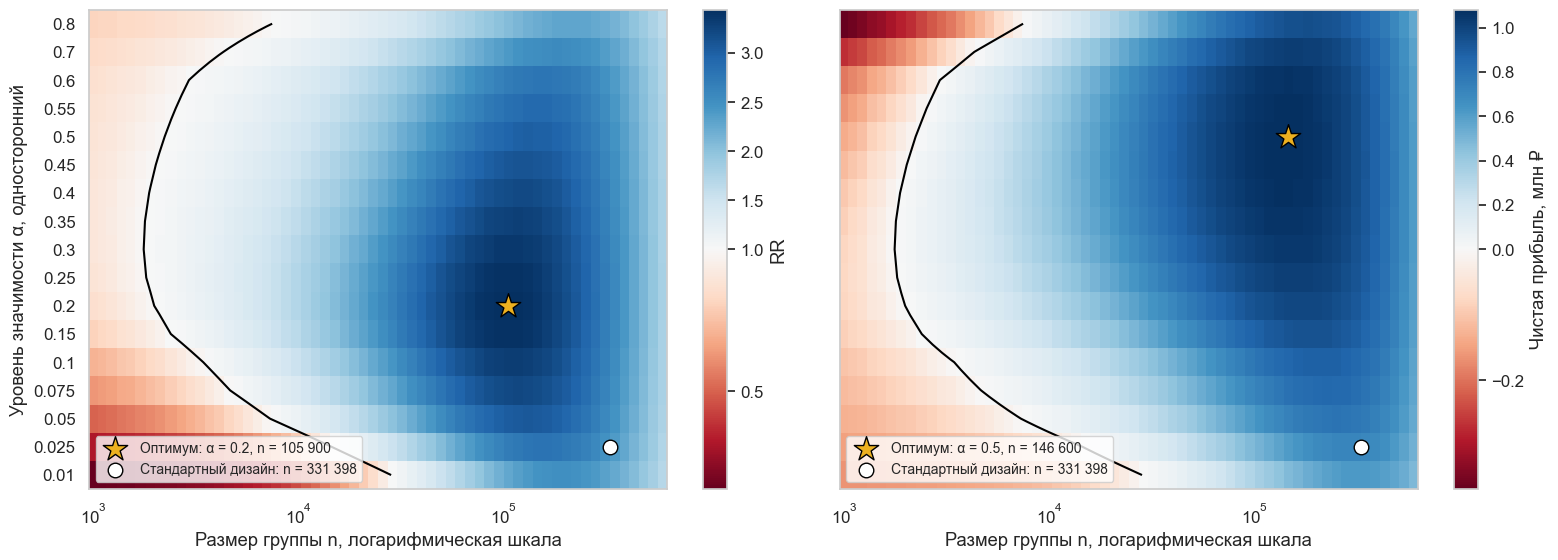

In [10]:
def plot_design_maps(case: BusinessCase, grid: dict, marks: dict = None) -> None:
    """Рисует тепловые карты RR и прибыли на сетке alpha и n."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), sharey=True)
    panels = [(axes[0], grid['rr'], 1, 'RR', 'rr'), (axes[1], grid['net'] / 1e6, 0, 'Чистая прибыль, млн ₽', 'net')]

    for ax, values, center, label, metric in panels:
        low, high = values.min(), values.max()
        if not low < center < high:
            low, high = min(low, center - 1e-6), max(high, center + 1e-6)
        mesh = ax.pcolormesh(n_grid, np.arange(alpha_grid.size), values, cmap='RdBu', shading='nearest',
                             norm=TwoSlopeNorm(vmin=low, vcenter=center, vmax=high))
        fig.colorbar(mesh, ax=ax, label=label)
        ax.contour(n_grid, np.arange(alpha_grid.size), values, levels=[center], colors='black', linewidths=1.5)

        best_alpha, best_n, *_ = best_design(grid, metric)
        ax.scatter(best_n, np.searchsorted(alpha_grid, best_alpha), marker='*', s=340, color='#EDB120', edgecolor='black', zorder=4,
                   label=f'Оптимум: α = {best_alpha}, n = {spaced(best_n)}')
        for name, (mark_alpha, mark_n) in (marks or {}).items():
            ax.scatter(mark_n, np.searchsorted(alpha_grid, mark_alpha), marker='o', s=110, color='white', edgecolor='black', zorder=4,
                       label=name)
        ax.set_xscale('log')
        ax.set_xlabel('Размер группы n, логарифмическая шкала')
        ax.legend(loc='lower left', fontsize=10)
        ax.grid(False)

    axes[0].set_yticks(np.arange(alpha_grid.size), alpha_grid)
    axes[0].set_ylabel('Уровень значимости α, односторонний')
    plt.tight_layout()
    plt.show()


mde_relative = 0.03  # стандартный дизайн: 80% мощности для эффекта 3% (одна σ априорного распределения)
delta = case.baseline_cr * mde_relative
variance = case.baseline_cr * (1 - case.baseline_cr)
n_standard = int(np.ceil(2 * variance * (norm.ppf(0.975) + norm.ppf(0.8)) ** 2 / delta ** 2))

plot_design_maps(case, grid, {f'Стандартный дизайн: n = {spaced(n_standard)}': (0.025, n_standard)})

Чёрная линия отделяет прибыльные дизайны (синие) от убыточных (красные).

Теперь сравним оптимумы со стандартным дизайном и с двумя решениями без теста. Решение «внедрить без теста» считает прибыль за весь горизонт: нет ни затрат на тест, ни задержки.

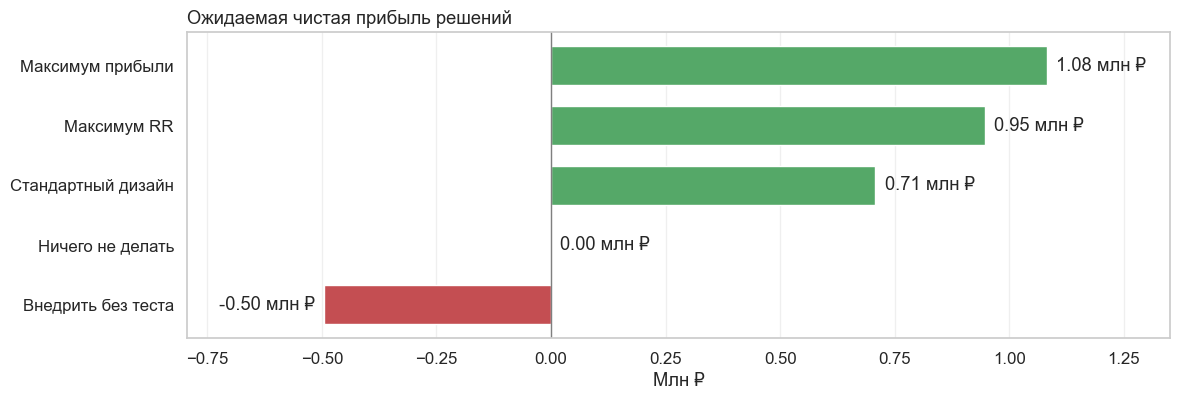

,"Чистая прибыль, ₽",RR,"Длительность, недель"
Внедрить без теста,-496300.17,NaN,NaN
Ничего не делать,0.00,NaN,NaN
Стандартный дизайн,707965.48,2.42,13.26
Максимум RR,947755.53,3.44,4.24
Максимум прибыли,1081315.68,3.00,5.86


In [11]:
horizon_revenue = case.weekly_revenue * case.horizon_weeks
ship_without_test = (np.trapezoid(horizon_revenue * effect_grid * density, effect_grid)
                     - case.implementation_cost - case.maintenance_cost
                     - case.rollback_cost * np.trapezoid(density * (effect_grid < case.break_even), effect_grid))

rr_alpha, rr_n, *_ = best_design(grid, 'rr')
net_alpha, net_n, *_ = best_design(grid, 'net')

options = {'Внедрить без теста': (ship_without_test, np.nan, np.nan), 'Ничего не делать': (0.0, np.nan, np.nan)}
for name, (alpha, n) in {
    'Стандартный дизайн': (0.025, n_standard),
    'Максимум RR': (rr_alpha, rr_n),
    'Максимум прибыли': (net_alpha, net_n),
}.items():
    result = evaluate_design(case, effect_grid, density, n, alpha)
    options[name] = (float(result['net']), float(result['rr']), 2 * n / case.weekly_users)

comparison = pd.DataFrame(options, index=['Чистая прибыль, ₽', 'RR', 'Длительность, недель']).T

ordered = comparison['Чистая прибыль, ₽'].sort_values()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.barh(ordered.index, ordered.values / 1e6, color=[GREEN if value > 0 else RED for value in ordered.values], height=0.65)
for position, value in enumerate(ordered.values):
    ax.text(value / 1e6 + (0.02 if value >= 0 else -0.02), position, f'{value / 1e6:.2f} млн ₽', va='center',
            ha='left' if value >= 0 else 'right')
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlim(ordered.min() / 1e6 * 1.6, ordered.max() / 1e6 * 1.25)
ax.set_title('Ожидаемая чистая прибыль решений', loc='left')
ax.set_xlabel('Млн ₽')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

comparison.round(2)

Что мы видим:

* **Оптимум лежит внутри сетки.** Лучшие дизайны длятся 4–6 недель. Дальше потери от задержки внедрения перевешивают пользу от точности.
* **Критерии расходятся.** Максимум $RR$ даёт $\alpha = 0.2$ и около 106 тыс. на группу, а максимум прибыли даёт $\alpha = 0.5$ и около 147 тыс. на группу. Отношение поощряет экономию затрат, даже если абсолютная прибыль ниже: здесь разница составляет около 134 тыс. ₽. Если важен результат этого решения, смотрите на прибыль. Если тестов много, а ресурсов мало и нужна лучшая отдача на вложенный рубль, смотрите на отношение.
* **Стандартный дизайн прибылен, но не оптимален.** Здесь он длится 13 недель и приносит 0.71 млн ₽ против 1.08 млн ₽ у лучшего варианта. Он проигрывает и из-за строгого порога, и из-за отложенного внедрения.
* **Внедрение без теста убыточно** (около −0.5 млн ₽): при нулевом среднем ожидании половина вариантов вредна. Именно отбор вариантов и создаёт ценность теста.

Высокий $\alpha$ здесь нельзя считать универсальным рецептом. Модель нейтральна к риску: она смотрит только на среднюю прибыль, а не на разброс исходов отдельного решения. К тому же порог здесь сравнивается с точкой безубыточности, поэтому $\alpha = 0.5$ означает правило «внедряем, если оценка выше точки безубыточности».

**Попробуйте сами.** Запустите ячейку и посмотрите, как оптимум реагирует на бизнес-параметры. Сдвиньте среднее ожиданий в минус или увеличьте стоимость отката. При большом сокращении горизонта прибыльной зоны может не остаться совсем.

In [12]:
def optimum_demo(prior_mean: float = 0.0, prior_std: float = 3.0, horizon_months: int = 12, rollback: int = 250) -> None:
    """Пересчитывает карты дизайнов для других априорных ожиданий и бизнес-параметров, проценты и тысячи рублей."""
    custom_case = BusinessCase(horizon_months=horizon_months, rollback_cost=rollback * 1_000)
    effects = np.linspace(-0.15, 0.15, 400)
    weights = norm.pdf(effects, prior_mean / 100, prior_std / 100)
    weights /= np.trapezoid(weights, effects)
    plot_design_maps(custom_case, design_grid(custom_case, effects, weights))


interact(optimum_demo,
         prior_mean=FloatSlider(value=0, min=-2, max=2, step=0.25, description='μ, %'),
         prior_std=FloatSlider(value=3, min=1, max=6, step=0.5, description='σ, %'),
         horizon_months=IntSlider(value=12, min=3, max=36, step=3, description='Горизонт'),
         rollback=IntSlider(value=250, min=0, max=2000, step=50, description='Откат, тыс'));

Как меняется оптимум при других ожиданиях:

In [13]:
sensitivity = []
for name, mean, std, months, rollback in [
    ('Базовый кейс', 0.0, 0.03, 12, 250_000),
    ('Ждём ухудшение: μ = -1%', -0.01, 0.03, 12, 250_000),
    ('Ждём улучшение: μ = +1%', 0.01, 0.03, 12, 250_000),
    ('Узкие ожидания: σ = 1.5%', 0.0, 0.015, 12, 250_000),
    ('Горизонт 36 месяцев', 0.0, 0.03, 36, 250_000),
    ('Дорогой откат: 2 млн ₽', 0.0, 0.03, 12, 2_000_000),
]:
    custom_case = BusinessCase(horizon_months=months, rollback_cost=rollback)
    effects = np.linspace(-0.15, 0.15, 600)
    weights = norm.pdf(effects, mean, std)
    weights /= np.trapezoid(weights, effects)
    best_alpha, best_n, best_rr, best_net = best_design(design_grid(custom_case, effects, weights), 'net')
    sensitivity.append({'Сценарий': name, 'α': best_alpha, 'n на группу': best_n,
                        'Недель': round(2 * best_n / custom_case.weekly_users, 1), 'Чистая прибыль, ₽': round(best_net)})

pd.DataFrame(sensitivity).set_index('Сценарий')

,α,n на группу,Недель,"Чистая прибыль, ₽"
Сценарий,,,,
Базовый кейс,0.50,146600,5.9,1086309
Ждём ухудшение: μ = -1%,0.40,131500,5.3,469672
Ждём улучшение: μ = +1%,0.55,131500,5.3,1916090
Узкие ожидания: σ = 1.5%,0.40,226100,9.0,215957
Горизонт 36 месяцев,0.50,252000,10.1,4244691
Дорогой откат: 2 млн ₽,0.35,163300,6.5,986331


* **Ожидания сдвигают порог.** Если вариант скорее плох, оптимальный $\alpha$ падает до 0.4, а если скорее хорош, растёт до 0.55.
* **Дорогой откат делает порог строже:** $\alpha$ снижается до 0.35.
* **Длинный горизонт разрешает длинный тест:** при 36 месяцах оптимум составляет 10 недель, потому что задержка стоит относительно дешевле.
* **Узкие ожидания требуют большей выборки:** эффекты малы, тест длится 9 недель, а прибыль падает примерно в 5 раз.

Оптимальный $\alpha$ здесь всюду намного выше 0.05, но это свойство кейса: цена ошибки мала по сравнению с выручкой за год. Для почти необратимых решений порог будет строже, поэтому расчёт нужно делать под конкретный тест.

## Проведение тестирования при $\alpha = 0.5$?

### Провокационный вопрос

Георгиев задаёт провокационный вопрос: **что если установить уровень значимости $\alpha = 0.5$?** Для простоты сравним с нулём, то есть возьмём $\theta_{BE} = 0$.

На первый взгляд это абсурдно. Кажется, что такой тест равносилен подбрасыванию монетки. Но это неверное прочтение $\alpha$:

* $\alpha$ — это вероятность внедрения **при нулевом эффекте**, а не вероятность ошибки в любом решении. Доля ошибочных внедрений зависит ещё и от распределения реальных эффектов.
* Монетка внедряла бы вариант с вероятностью 50% **независимо от эффекта**, а тест с односторонним $\alpha = 0.5$ внедряет вариант, если его оценка эффекта положительна, поэтому вероятность внедрения растёт с эффектом.

### Асимметрия вероятности внедрения

Асимметрия возникает потому, что **решение одностороннее**: мы внедряем вариант, только если его оценка достаточно высока. Ухудшение значимым образом не приводит к внедрению, и поэтому хорошие и плохие варианты имеют разные шансы.

В основе теста лежит сравнение конверсий контрольной ($p_0$) и тестовой ($p_1$) групп:

$$
z = \frac{\hat{p}_1 - \hat{p}_0}{SE}, \quad \text{где} \quad SE = \sqrt{\frac{p_0(1-p_0)}{n} + \frac{p_1(1-p_1)}{n}}
$$

Если эффекта нет, то $z \sim N(0, 1)$. Если эффект есть, распределение сдвигается на **параметр нецентральности** со знаком:

$$
\text{NCP} = \frac{p_1 - p_0}{SE}
$$

Мы отвергаем $H_0$ и внедряем вариант, если $z > z_{1-\alpha}$. Вероятность этого равна:

$$
P(\text{внедрение}) = 1 - \Phi(z_{1-\alpha} - \text{NCP})
$$

Рассмотрим два случая:

* **Положительный эффект ($p_1 > p_0$):** $\text{NCP} > 0$, и с ростом эффекта вероятность стремится к 1. Это мощность.
* **Отрицательный эффект ($p_1 < p_0$):** $\text{NCP} < 0$, и с ростом ухудшения вероятность стремится к 0. Это уже не мощность, а вероятность внедрить плохой вариант.

Скорость этих переходов определяется величиной $\text{NCP}$, то есть **размером выборки**. Анимация показывает, как при росте выборки обе кривые становятся круче.

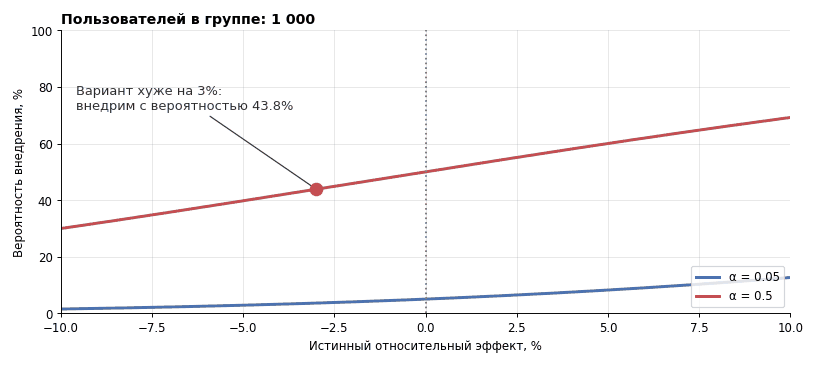

In [14]:
effects_table = np.array([-0.05, -0.03, 0.0, 0.03, 0.05])
table = pd.DataFrame(index=[f'{value:+.0%}' for value in effects_table])
table.index.name = 'Истинный эффект'
for n_val in [10_000, 100_000]:
    for alpha_val in [0.05, 0.5]:
        table[f'n = {n_val}, α = {alpha_val}'] = implementation_probability(
            case.baseline_cr, effects_table, 0.0, n_val, alpha_val).round(3)

table

,"n = 10000, α = 0.05","n = 10000, α = 0.5","n = 100000, α = 0.05","n = 100000, α = 0.5"
Истинный эффект,,,,
-5%,0.007,0.206,0.000,0.005
-3%,0.016,0.312,0.001,0.061
+0%,0.050,0.500,0.050,0.500
+3%,0.123,0.686,0.454,0.937
+5%,0.200,0.789,0.813,0.994


Таблица показывает, что всё зависит от выборки. При $n = 10\,000$ тест слабый: вариант на 3% хуже контроля будет внедрён при $\alpha = 0.5$ с вероятностью 31%. При $n = 100\,000$ эта вероятность падает до 6%. При нулевом эффекте вероятность внедрения равна $\alpha$ при любом $n$.

Чтобы оценить риск целиком, посчитаем для априорного распределения, какая доля внедрений окажется ошибочной и какой средний эффект получит продукт за одно решение. Сравниваем монетку с тестами при $\theta_{BE} = 0$ и без учёта затрат.

In [15]:
def rollout_quality(n_per_group: int, alpha: float) -> pd.Series:
    """Считает долю внедрений, долю ошибочных внедрений и средний эффект для априорного распределения."""
    if alpha is None:  # монетка
        probability = np.full_like(effect_grid, 0.5)
    else:
        probability = implementation_probability(case.baseline_cr, effect_grid, 0.0, n_per_group, alpha)
    p_ship = np.trapezoid(probability * density, effect_grid)
    p_bad_ship = np.trapezoid(probability * density * (effect_grid < 0), effect_grid)
    return pd.Series({
        'Доля внедрений': p_ship,
        'Доля плохих среди внедрённых': p_bad_ship / p_ship,
        'Средний эффект на решение, %': np.trapezoid(effect_grid * probability * density, effect_grid) * 100,
    })


pd.DataFrame({
    'Монетка': rollout_quality(0, None),
    'n = 10 000, α = 0.05': rollout_quality(10_000, 0.05),
    'n = 10 000, α = 0.5': rollout_quality(10_000, 0.5),
    'n = 100 000, α = 0.05': rollout_quality(100_000, 0.05),
    'n = 100 000, α = 0.5': rollout_quality(100_000, 0.5),
}).T.round(3)

,Доля внедрений,Доля плохих среди внедрённых,"Средний эффект на решение, %"
Монетка,0.500,0.500,0.000
"n = 10 000, α = 0.05",0.069,0.180,0.171
"n = 10 000, α = 0.5",0.499,0.356,0.520
"n = 100 000, α = 0.05",0.183,0.028,0.662
"n = 100 000, α = 0.5",0.499,0.183,1.000


* **Монетка** внедряет половину вариантов, половина внедрённых плоха, а средний эффект равен нулю.
* **Тест с $\alpha = 0.5$** внедряет столько же, но плохих среди внедрённых заметно меньше: 36% при $n = 10\,000$ и 18% при $n = 100\,000$. Средний эффект положителен.
* **Строгий порог при той же выборке** даёт меньше плохих внедрений (18% и 3%), но пропускает хорошие варианты, и средний эффект оказывается ниже.

Итак, $\alpha = 0.5$ — не монетка, но и не бесплатный подарок: среди внедрённых останется заметная доля плохих вариантов, а защищает от них только выборка. Георгиев тоже подчёркивает, что этот пример не означает, будто тестировать на 50% лучше, чем на 95%: оптимальный порог зависит от всех параметров.

**Попробуйте сами.** Подвигайте $\alpha$ и $n$. Цифры над графиком показывают вероятность внедрить вариант, который на 3% хуже контроля, и вариант, который на 3% лучше.

In [16]:
def asymmetry_demo(alpha: float = 0.5, n_thousands: int = 10) -> None:
    """Сравнивает вероятность внедрения при выбранных alpha и n с дизайном alpha = 0.05."""
    n = n_thousands * 1_000
    effects = np.linspace(-0.15, 0.15, 500)
    chosen = implementation_probability(case.baseline_cr, effects, 0.0, n, alpha)
    reference = implementation_probability(case.baseline_cr, effects, 0.0, n, 0.05)
    worse, better = implementation_probability(case.baseline_cr, np.array([-0.03, 0.03]), 0.0, n, alpha)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(effects * 100, reference * 100, color=GRAY, linewidth=2, linestyle='--', label='α = 0.05')
    ax.plot(effects * 100, chosen * 100, color=BLUE, linewidth=2.5, label=f'α = {alpha:.2f}')
    ax.axhline(50, color=RED, linewidth=1.5, linestyle=':', label='Монетка')
    ax.axvline(0, color=GRAY, linestyle=':', linewidth=1.5)
    ax.set_title(f'n = {n}: вариант хуже на 3% внедрим с вероятностью {worse:.1%}, лучше на 3% с вероятностью {better:.1%}', loc='left', fontsize=12)
    ax.set_xlabel('Истинный относительный эффект, %')
    ax.set_ylabel('Вероятность внедрения, %')
    ax.set_ylim(0, 100)
    ax.set_xlim(-15, 15)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


interact(asymmetry_demo,
         alpha=FloatSlider(value=0.5, min=0.01, max=0.8, step=0.01, description='α'),
         n_thousands=IntSlider(value=10, min=1, max=300, step=1, description='n, тыс'));

## Ограничения модели

### Кратко

1. **Упрощённое распределение ожиданий.** На практике оно может быть сложнее и асимметричнее.
2. **Постоянный эффект.** Эффект может затухать со временем (novelty effect).
3. **Долгосрочные эффекты.** Некоторые изменения влияют на LTV, бренд и лояльность.
4. **Альтернативные издержки.** Время и ресурсы на тест можно потратить иначе.
5. **Проблема референтного класса.** Выбор априорного распределения субъективен.
6. **Упрощённый откат.** Модель считает откат платным, но потери после ошибочного внедрения идут весь горизонт, хотя откат их бы прервал. Откат здесь считается пессимистично.
7. **Фиксированные затраты в пороге.** К моменту решения затраты на тест уже понесены, поэтому в точке безубыточности для решения их можно не учитывать. Мы следуем исходной постановке, где они включены.

Тем не менее подход даёт практический фреймворк для выбора дизайна с учётом бизнес-контекста.

### Развёрнуто

Расчёт отношения выгоды к риску точен настолько, насколько точны исходные данные. Если распределение ожиданий искажено, затраты недооценены или выгоды преувеличены, «оптимальный» дизайн на самом деле оптимальным не будет. То же верно для ошибки в горизонте использования. Существует «достаточно хороший» уровень оценки, который уравновешивает сложность получения точных оценок и их пользу.

**Долгосрочные эффекты.** Они мешают A/B-тестам вообще: и затраты, и выгоды трудно измерить в краткосрочном эксперименте при изменчивости продукта, технологий, ожиданий пользователей и рынка. Модель предполагает, что эффект примерно одинаков весь горизонт, но эффекты новизны исчезают, а внешние обстоятельства меняются.

**Постоянные изменения пользовательского опыта.** Продукты с большим числом тестов могут страдать от самого факта частых изменений независимо от результатов. Если главная страница и корзина меняются каждый месяц, это может негативно влиять на пользователей, особенно на сервисах с частыми возвращениями. Этот эффект мало изучен, но о нём стоит помнить.

**Альтернативная стоимость.** Деньги и время, потраченные на тест, можно вложить во что-то другое. Некоторым компаниям выгоднее отказаться от теста и пойти на больший риск. A/B-тест — средство достижения цели, а не сама цель.

Ответить на вопрос об альтернативной стоимости помогает сравнение с решением без теста, которое мы сделали выше: оно показывает, сколько на самом деле добавляет тестирование.

## Заключение

* Стандартные $\alpha = 0.05$ и мощность 80% — это соглашение, а не оптимум для бизнеса.
* Дизайн можно подбирать под деньги: нужны затраты, выручка, горизонт и распределение ожидаемых эффектов.
* Цель нужно выбирать явно: максимум отношения выгоды к риску и максимум прибыли дают разные дизайны.
* Модель обязана учитывать цену времени, иначе «оптимальная» выборка будет бесконечно расти.
* Высокое $\alpha$ не равно монетке, но и не безопасно само по себе: защита от плохих вариантов зависит от размера выборки.
* Чем дороже и необратимее ошибка, тем строже оптимальный порог, поэтому результат нужно проверять на чувствительность к ожиданиям и затратам.